### Відбір і підготовка даних

Залишено аукціони зі статусом **«Аукціон завершено»**, для яких можна порівняти стартову та фінальну орендну плату. Рядки з відсутньою, нульовою або від’ємною нормативною грошовою оцінкою (НГО) виключено: такі значення не дають змоги коректно врахувати НГО в моделі та логарифмувати її. Після відбору залишилося **22 275 аукціонів**.

НГО, стартову та фінальну плату перераховано **на один гектар**, щоб порівнювати ділянки різної площі. Фінальна плата за гектар — показник, який прогнозують моделі.

### Обрані характеристики

Для прогнозування використано такі характеристики ділянки та умов оренди:

| Характеристика | Навіщо її враховано |
|---|---|
| Площа ділянки | Плата за гектар може відрізнятися для малих і великих ділянок. |
| НГО за гектар | Враховує відмінності в нормативній оцінці землі. |
| Область | Враховує регіональні відмінності земельного ринку. |
| Код цільового призначення КВЦПЗ | Показує, для якого використання призначена ділянка. |
| Тип власності | Дозволяє врахувати відмінності між ділянками різних форм власності. |
| Строк оренди | Умови та тривалість користування можуть бути пов’язані з орендною платою. |

Додатково враховано дві часові змінні:

- **Календарний місяць** — для врахування сезонних відмінностей.
- **Кількість місяців від листопада 2021 року** — для врахування загальної зміни рівня плати з часом.

Ці показники допомагають порівнювати аукціони з урахуванням відмінностей між ділянками та часом проведення торгів.

### Роль стартової ціни

Для кожного методу порівнюються дві моделі:

- **Без стартової ціни** — використовує характеристики ділянки, умови оренди та часові змінні.
- **Зі стартовою ціною** — додатково використовує стартову плату за гектар.

Таке порівняння показує, чи додає стартова ціна корисну інформацію для прогнозування фінальної плати.

### Навчальна та тестова вибірки

Дані випадково розділено за кадастровими номерами: приблизно **80% ділянок** віднесено до навчальної частини, **20%** — до тестової. Усі аукціони однієї ділянки потрапляють лише в одну частину. Це запобігає ситуації, коли модель навчається на ділянці, а потім перевіряється на іншому аукціоні тієї самої ділянки.

Навчальна вибірка містить **17 812 аукціонів**, тестова — **4 463**. Для всіх моделей використано однакове розбиття. Моделі навчаються на навчальній частині, а якість їхніх прогнозів оцінюється на тестовій.

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import GroupShuffleSplit
import statsmodels.formula.api as smf
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.tree import DecisionTreeRegressor
from patsy import cr
import altair as alt
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)
df_load = pd.read_csv('Prozoro_sales_cleaned.csv')
df_load.head()

,Unnamed: 0,Ідентифікатор аукціону,Посилання на портал,Тип процедури продажу,Статус аукціону,Планова дата аукціону,Організатор,Код організатора,Тип ідентифіктора,Виставлена вартість,...,lease_ha_usd,lease_ha_eur,lease_duration_years_int,days_to_contract,same_cadastral_multiple_auctions,area_from_api,real_income_api,area_original,Дохід_original,price_change_pct
0,47104,LRE001-UA-20211006-94037,https://prozorro.sale/auction/LRE001-UA-20211006-94037,Земельні торги - оренда,Аукціон завершено,2021-11-09,ТАВРИЧАНСЬКА СІЛЬСЬКА РАДА КАХОВСЬКОГО РАЙОНУ ХЕРСОНСЬКОЇ ОБЛАСТІ,26519001,UA-EDR,5088.42,...,118.697970,102.498271,7,16.0,False,2.1000,6501.00,2.1000,6501.00,27.760680
1,47107,LRE001-UA-20211008-29258,https://prozorro.sale/auction/LRE001-UA-20211008-29258,Земельні торги - оренда,Аукціон завершено,2021-11-10,ТАВРИЧАНСЬКА СІЛЬСЬКА РАДА КАХОВСЬКОГО РАЙОНУ ХЕРСОНСЬКОЇ ОБЛАСТІ,26519001,UA-EDR,5021.42,...,96.395358,83.264592,7,12.0,False,6.6000,16600.42,6.6000,16600.42,230.592143
2,47108,LRE001-UA-20211008-38790,https://prozorro.sale/auction/LRE001-UA-20211008-38790,Земельні торги - оренда,Аукціон завершено,2021-11-09,Лопатинська селищна рада,4369819,UA-EDR,22999.49,...,438.064336,378.278053,7,6.0,True,14.0044,160000.00,14.0044,160000.00,595.667600
3,47109,LRE001-UA-20211008-67143,https://prozorro.sale/auction/LRE001-UA-20211008-67143,Земельні торги - оренда,Аукціон завершено,2021-11-11,ТАВРИЧАНСЬКА СІЛЬСЬКА РАДА КАХОВСЬКОГО РАЙОНУ ХЕРСОНСЬКОЇ ОБЛАСТІ,26519001,UA-EDR,47589.83,...,151.978186,131.485912,7,14.0,False,19.6400,77777.77,19.6400,77777.77,63.433595
4,47110,LRE001-UA-20211011-76244,https://prozorro.sale/auction/LRE001-UA-20211011-76244,Земельні торги - оренда,Аукціон завершено,2021-11-11,Згурівська селищна рада,4360296,UA-EDR,18042.74,...,385.085371,333.161636,7,15.0,False,6.1987,62200.00,6.1987,62200.00,244.736997


In [2]:
df = df_load.loc[df_load['Статус аукціону'] == "Аукціон завершено",
 [
    'Ідентифікатор аукціону',
    'Посилання на портал',
    'Площа земельної ділянки, ГА',
    'Дохід',
    'область',
    'КВЦПЗ код класифікатора товару',
    'Тип власності',
    'lease_duration_years_int',
    'Нормативна грошова оцінка',
    'Виставлена вартість',
    'Планова дата аукціону',
    'Кадастровий номер',
    'Дата аукціону'
]].copy()
df = df.loc[df['Нормативна грошова оцінка']>0, :]

df['ngo_per_ha'] = df['Нормативна грошова оцінка'] / df['Площа земельної ділянки, ГА']
df['start_per_ha'] = df['Виставлена вартість'] / df['Площа земельної ділянки, ГА']
df['final_per_ha'] = df['Дохід'] / df['Площа земельної ділянки, ГА']

date = pd.to_datetime(df['Дата аукціону'],errors='coerce')
df['calendar_month'] = date.dt.month
df['time_trend'] = ((date.dt.year - 2021) * 12 + date.dt.month - 11)

df.sample(5)

,Ідентифікатор аукціону,Посилання на портал,"Площа земельної ділянки, ГА",Дохід,область,КВЦПЗ код класифікатора товару,Тип власності,lease_duration_years_int,Нормативна грошова оцінка,Виставлена вартість,Планова дата аукціону,Кадастровий номер,Дата аукціону,ngo_per_ha,start_per_ha,final_per_ha,calendar_month,time_trend
11655,LRE001-UA-20241202-03547,https://prozorro.sale/auction/LRE001-UA-20241202-03547,2.0000,19280.00,Вінницька область,1.03,Приватна,7,35292.25,18000.00,2025-01-03,0522884800:06:002:0150,2025-01-03,17646.125000,9000.000000,9640.000000,1,38
12677,LRE001-UA-20250217-99091,https://prozorro.sale/auction/LRE001-UA-20250217-99091,6.3000,145132.00,Сумська область,1.01,Державна,14,193181.78,23181.81,2025-03-31,5922081100:07:001:2048,2025-03-31,30663.774603,3679.652381,23036.825397,3,40
20871,LRE001-UA-20260326-60043,https://prozorro.sale/auction/LRE001-UA-20260326-60043,2.3217,4645.00,Рівненська область,1.01,Комунальна,7,13793.17,1655.18,2026-04-27,5625485400:05:003:0294,2026-04-27,5940.978593,712.917259,2000.689150,4,53
19731,LRE001-UA-20260123-89704,https://prozorro.sale/auction/LRE001-UA-20260123-89704,2.9799,61199.96,Полтавська область,1.01,Комунальна,7,119577.95,59995.82,2026-02-25,5325755100:00:026:0029,2026-02-25,40128.175442,20133.501124,20537.588510,2,51
852,LRE001-UA-20211230-60562,https://prozorro.sale/auction/LRE001-UA-20211230-60562,4.4368,18000.00,Рівненська область,1.01,Комунальна,7,24708.03,2964.96,2022-02-01,5623481600:03:006:0007,2022-02-01,5568.885233,668.265417,4056.978002,2,3


In [3]:
categorical_cols = [
    'область',
    'КВЦПЗ код класифікатора товару',
    'Тип власності',
    'calendar_month',
]
for col in categorical_cols:
    df[col] = df[col].astype('category')

date_cols = [
    'Планова дата аукціону',
    'Дата аукціону',
]
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors='raise')


In [4]:
features_without_start = [
    'Площа земельної ділянки, ГА',
    'ngo_per_ha',
    'область',
    'КВЦПЗ код класифікатора товару',
    'Тип власності',
    'lease_duration_years_int',
    'calendar_month',
    'time_trend',
]
features_with_start = features_without_start +['start_per_ha']
target = 'final_per_ha'

split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
groups = df['Кадастровий номер'].astype('string')
groups = groups.fillna('auction:' + df['Ідентифікатор аукціону'].astype('string'))
train_idx, test_idx = next(split.split(df, groups=groups))
train = df.iloc[train_idx].copy()
test = df.iloc[test_idx].copy()

X_train_without_start = train[features_without_start].copy()
X_train_with_start = train[features_with_start].copy()
y_train = train[target].copy()

X_test_without_start = test[features_without_start].copy()
X_test_with_start = test[features_with_start].copy()
y_test = test[target].copy()

print('Випадковий поділ за кадастровими номерами; random_state=42')
print('Навчання:', len(train), 'аукціонів')
print('Тест:', len(test), 'аукціонів')
print('\nРозміри таблиць:')
print('Навчання без старту:', X_train_without_start.shape)
print('Навчання зі стартом:', X_train_with_start.shape)
print('Тест без старту:', X_test_without_start.shape)
print('Тест зі стартом:', X_test_with_start.shape)

Випадковий поділ за кадастровими номерами; random_state=42
Навчання: 17812 аукціонів
Тест: 4463 аукціонів

Розміри таблиць:
Навчання без старту: (17812, 8)
Навчання зі стартом: (17812, 9)
Тест без старту: (4463, 8)
Тест зі стартом: (4463, 9)


### OLS без стартової ціни

$$
\begin{aligned}
\ln Y_i ={}&
\alpha_0
+ \alpha_1 \ln N_i
+ \alpha_2 \ln A_i
+ \alpha_3 L_i
+ \alpha_4 T_i \\
&+ \delta^{(0)}_{r(i)}
+ \gamma^{(0)}_{k(i)}
+ \theta^{(0)}_{o(i)}
+ \mu^{(0)}_{m(i)}
+ \varepsilon_i^{(0)}.
\end{aligned}
$$

### OLS зі стартовою ціною

$$
\begin{aligned}
\ln Y_i ={}&
\beta_0
+ \beta_1 \ln N_i
+ \beta_2 \ln A_i
+ \beta_3 L_i
+ \beta_4 T_i
+ \beta_5 \ln S_i \\
&+ \delta^{(1)}_{r(i)}
+ \gamma^{(1)}_{k(i)}
+ \theta^{(1)}_{o(i)}
+ \mu^{(1)}_{m(i)}
+ \varepsilon_i^{(1)}.
\end{aligned}
$$

Позначення:

- $Y_i$ — фінальна річна орендна плата за гектар.
- $S_i$ — стартова річна орендна плата за гектар.
- $N_i$ — нормативна грошова оцінка за гектар.
- $A_i$ — площа ділянки в гектарах.
- $L_i$ — строк оренди в роках.
- $T_i$ — кількість місяців від листопада 2021 року.
- $\delta_{r(i)}$ — ефект області.
- $\gamma_{k(i)}$ — ефект цільового призначення КВЦПЗ.
- $\theta_{o(i)}$ — ефект типу власності.
- $\mu_{m(i)}$ — ефект календарного місяця.
- $\varepsilon_i$ — випадкова похибка.

Категоріальні ефекти задаються індикаторними змінними з однією
базовою категорією для кожної ознаки. Коефіцієнти двох моделей
оцінюються окремо.


In [5]:
train_ols = train.copy()
test_ols = test.copy()
for data in [train_ols, test_ols]:
    data['ln_final_per_ha'] = np.log(data['final_per_ha'])
    data['ln_start_per_ha'] = np.log(data['start_per_ha'])
    data['ln_ngo_per_ha'] = np.log(data['ngo_per_ha'])
    data['ln_area'] = np.log(data['Площа земельної ділянки, ГА'])

formula_without_start = """
ln_final_per_ha ~ ln_ngo_per_ha + ln_area
+ lease_duration_years_int + time_trend
+ C(Q('область'))
+ C(Q('КВЦПЗ код класифікатора товару'))
+ C(Q('Тип власності'))
+ C(calendar_month)
"""

formula_with_start = formula_without_start + " + ln_start_per_ha"

ols_without_start = smf.ols(
    formula_without_start, data=train_ols
).fit(cov_type='HC3')

ols_with_start = smf.ols(
    formula_with_start, data=train_ols
).fit(cov_type='HC3')

print(ols_without_start.summary())
print(ols_with_start.summary())

                            OLS Regression Results                            
Dep. Variable:        ln_final_per_ha   R-squared:                       0.363
Model:                            OLS   Adj. R-squared:                  0.361
Method:                 Least Squares   F-statistic:                     134.6
Date:                Thu, 22 Oct 2026   Prob (F-statistic):               0.00
Time:                        00:34:14   Log-Likelihood:                -23033.
No. Observations:               17812   AIC:                         4.618e+04
Df Residuals:                   17754   BIC:                         4.663e+04
Df Model:                          57                                         
Covariance Type:                  HC3                                         
                                                     coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------

In [6]:
pred_without_start = ols_without_start.predict(test_ols)
pred_with_start = ols_with_start.predict(test_ols)
y_test_log = test_ols['ln_final_per_ha']

results = pd.DataFrame({
    'Модель': ['OLS без старту', 'OLS зі стартом'],
    'MAE (log)': [mean_absolute_error(y_test_log, pred_without_start), mean_absolute_error(y_test_log, pred_with_start),],
    'RMSE (log)': [np.sqrt(mean_squared_error(y_test_log, pred_without_start)),
        np.sqrt(mean_squared_error(y_test_log, pred_with_start)),],
})

results

,Модель,MAE (log),RMSE (log)
0,OLS без старту,0.715573,0.887743
1,OLS зі стартом,0.705509,0.871626


In [10]:
plot_data = pd.DataFrame({
    'actual': test_ols['ln_final_per_ha'].to_numpy(),
    'predicted': np.asarray(pred_with_start)
})
limits = [plot_data.min().min(), plot_data.max().max()]
points = alt.Chart(plot_data).mark_circle(
    size=20, opacity=.25
).encode(
    x=alt.X('actual:Q', title='Фактична ln(Плата/га)',
            scale=alt.Scale(domain=limits, zero=False)),
    y=alt.Y('predicted:Q', title='Прогнозована ln(Плата/га)',
            scale=alt.Scale(domain=limits, zero=False))
)
diagonal = alt.Chart(pd.DataFrame({
    'actual': limits,
    'predicted': limits
})).mark_line(color='red', strokeDash=[5, 5]).encode(
    x='actual:Q',
    y='predicted:Q'
)
(points + diagonal).properties(
    width=500, height=500,
    title=alt.TitleParams(
        text='OLS зі стартом: фактичні та прогнозовані значення',
        subtitle=['Сині точки — тестові аукціони: факт по X, прогноз по Y.', 'Червоний пунктир — точний прогноз.'],
        subtitleFontSize=12, subtitlePadding=8
    ))

alt.LayerChart(...)

Додавання стартової ціни до OLS покращило прогноз фінальної орендної плати: на тестовій вибірці MAE зменшилася з **0,7156 до 0,7055** (на **1,41%**), а RMSE -- з **0,8877 до 0,8716** (на **1,82%**). Обидва показники обчислено в логарифмічній шкалі.

Коефіцієнт логарифма стартової ціни становить **0,503**: за незмінних інших характеристик вищий на 1% старт пов’язаний приблизно з вищою на 0,5% фінальною платою.

Графік демонструє загальну відповідність прогнозів фактичним значенням, проте модель часто завищує низькі та занижує високі значення. Отримані результати підтримують H1 на поточному розбитті, хоча покращення прогнозу невелике.

### Модель зі сплайном стартової ціни

$$
\begin{aligned}
\ln Y_i ={}&
\beta_0
+ \beta_1 \ln N_i
+ \beta_2 \ln A_i
+ \beta_3 L_i
+ \beta_4 T_i \\
&+ \delta_{r(i)}
+ \gamma_{k(i)}
+ \theta_{o(i)}
+ \mu_{m(i)}
+ \sum_{j=1}^{5}\eta_j B_j(\ln S_i)
+ \varepsilon_i.
\end{aligned}
$$

Позначення:

- $Y_i$ — фінальна річна орендна плата за гектар.
- $S_i$ — стартова річна орендна плата за гектар.
- $N_i$ — нормативна грошова оцінка за гектар.
- $A_i$ — площа ділянки в гектарах.
- $L_i$ — строк оренди в роках.
- $T_i$ — кількість місяців від листопада 2021 року.
- $\delta_{r(i)}$ — ефект області.
- $\gamma_{k(i)}$ — ефект цільового призначення КВЦПЗ.
- $\theta_{o(i)}$ — ефект типу власності.
- $\mu_{m(i)}$ — ефект календарного місяця.
- $B_j(\ln S_i)$ — базисні функції натурального кубічного сплайна.
- $\eta_j$ — коефіцієнти сплайна, оцінені за навчальними даними.
- $\varepsilon_i$ — випадкова похибка.

Сплайн із `df=5` описує залежність від логарифма стартової ціни через п’ять базисних компонентів, дозволяючи її нахилу плавно змінюватися. Компоненти задаються з обмеженням центрування (`constraints='center'`), щоб їхній сумарний внесок не дублював вільний член моделі. Коефіцієнти оцінюються методом найменших квадратів.

In [11]:
formula_spline = (formula_without_start + " + cr(ln_start_per_ha, df=5, constraints='center')")

spline_with_start = smf.ols(formula_spline,data=train_ols).fit(cov_type='HC3')

spline_pred_without_start = ols_without_start.predict(test_ols)
spline_pred_with_start = spline_with_start.predict(test_ols)
results_spline = pd.DataFrame({
    'Модель': ['Без старту', 'Зі сплайном старту'],
    'MAE (log)': [
        mean_absolute_error(y_test_log, spline_pred_without_start),
        mean_absolute_error(y_test_log, spline_pred_with_start)],
    'RMSE (log)': [
        np.sqrt(mean_squared_error(y_test_log, spline_pred_without_start)),
        np.sqrt(mean_squared_error(y_test_log, spline_pred_with_start))]
})

results_spline

,Модель,MAE (log),RMSE (log)
0,Без старту,0.715573,0.887743
1,Зі сплайном старту,0.701637,0.869622


In [12]:
d = pd.concat([train_ols.iloc[[0]]] * 100, ignore_index=True)
d['ln_start_per_ha'] = np.linspace(
    train_ols['ln_start_per_ha'].quantile(.01),
    train_ols['ln_start_per_ha'].quantile(.99), 100
)

p = spline_with_start.get_prediction(d).summary_frame()
p['Старт'] = d['ln_start_per_ha'].to_numpy()
p['Сплайн'] = p['mean']
p['OLS'] = ols_with_start.predict(d).to_numpy()

base = alt.Chart(p).encode(
    x=alt.X('Старт:Q', title='ln(Старт/га)', scale=alt.Scale(zero=False))
)

band = base.mark_area(opacity=.15).encode(
    y=alt.Y('mean_ci_lower:Q', title='ln(Плата/га)',
            scale=alt.Scale(zero=False)),
    y2='mean_ci_upper:Q'
)

lines = base.transform_fold(
    ['Сплайн', 'OLS'], as_=['Модель', 'Прогноз']
).mark_line().encode(
    y='Прогноз:Q',
    color='Модель:N',
    strokeDash='Модель:N'
)

(band + lines).properties(width=500, height=400)

alt.LayerChart(...)

Сплайн показує зростаючу залежність фінальної плати від стартової, проте її нахил змінюється: на окремих ділянках зростання прискорюється або сповільнюється. Вираженої U-подібної форми в показаному діапазоні немає. Відхилення від прямої OLS помірні.

Інші характеристики зафіксовано на значеннях однієї навчальної ділянки. Затінення позначає точковий 95% довірчий інтервал очікуваного логарифма фінальної плати.

In [14]:
spline_points = alt.Chart(pd.DataFrame({
    'actual': test_ols['ln_final_per_ha'].to_numpy(),
    'predicted': np.asarray(spline_pred_with_start)
})).mark_circle(size=20, opacity=.25).encode(
    x=alt.X('actual:Q', title='Фактична ln(Плата/га)',
            scale=alt.Scale(domain=limits, zero=False)),
    y=alt.Y('predicted:Q', title='Прогнозована ln(Плата/га)',
            scale=alt.Scale(domain=limits, zero=False))
)

(spline_points + diagonal).properties(
    width=500, height=500,
    title=alt.TitleParams(
        text='Сплайн: фактичні та прогнозовані значення',
        subtitle=['Сині точки — тестові аукціони: факт по X, прогноз по Y.', 'Червоний пунктир — точний прогноз.'],
        subtitleFontSize=12, subtitlePadding=8
    )
)

alt.LayerChart(...)

Прогнози сплайнової моделі загалом зростають разом із фактичними значеннями. Водночас зберігається тенденція до завищення низьких і заниження високих значень фінальної плати. Отже, гнучкіша форма залежності від старту не усуває значних помилок для крайніх спостережень. 

Додавання сплайна стартової ціни зменшило тестову MAE з **0,7156 до 0,7016** (на **1,95%**), а RMSE — з **0,8877 до 0,8696** (на **2,04%**) порівняно з моделлю без старту. Усі показники обчислено в логарифмічній шкалі.

Порівняно зі звичайною OLS зі стартовою ціною покращення менше: **0,55% за MAE** та **0,23% за RMSE**. Таким чином, стартова ціна додає інформацію для прогнозування, а врахування її нелінійної залежності дає невелике додаткове покращення. Результат підтримує H1 на поточному розбитті


## CART

In [15]:
X_train_cart = pd.get_dummies(X_train_with_start)
X_test_cart = pd.get_dummies(X_test_with_start)
X_test_cart = X_test_cart.reindex(columns=X_train_cart.columns,fill_value=0)

y_train_log = np.log(y_train)
y_test_log = np.log(y_test)

cart_without_start = DecisionTreeRegressor(
    max_depth=10,
    min_samples_leaf=20,
    random_state=42
)

cart_with_start = DecisionTreeRegressor(
    max_depth=10,
    min_samples_leaf=20,
    random_state=42
)

cart_without_start.fit(X_train_cart.drop(columns='start_per_ha'),y_train_log)
cart_with_start.fit(X_train_cart, y_train_log)

cart_pred_without_start = cart_without_start.predict(X_test_cart.drop(columns='start_per_ha'))
cart_pred_with_start = cart_with_start.predict(X_test_cart)

results_cart = pd.DataFrame({
    'Модель': ['CART без старту', 'CART зі стартом'],
    'MAE (log)': [mean_absolute_error(y_test_log, cart_pred_without_start),
                mean_absolute_error(y_test_log, cart_pred_with_start)],
    'RMSE (log)': [
        np.sqrt(mean_squared_error(y_test_log, cart_pred_without_start)),
        np.sqrt(mean_squared_error(y_test_log, cart_pred_with_start))]
})

results_cart



,Модель,MAE (log),RMSE (log)
0,CART без старту,0.694336,0.881310
1,CART зі стартом,0.685487,0.868929


CART послідовно розділяє навчальні спостереження за характеристиками ділянки, обираючи пороги, які зменшують суму квадратів помилок. Прогноз у кінцевому листку — середній логарифм фінальної плати спостережень цього листка.

Оцінено дві моделі: без стартової ціни та з нею. Категоріальні змінні перетворено на індикаторні колонки. Максимальна глибина дерев становить **10**, мінімальна кількість спостережень у кінцевому листку — **20**.

In [17]:
cart_points = alt.Chart(pd.DataFrame({
    'actual': np.log(y_test).to_numpy(),
    'predicted': np.asarray(cart_pred_with_start)
})).mark_circle(size=20, opacity=.25).encode(
    x=alt.X('actual:Q', title='Фактична ln(Плата/га)',
            scale=alt.Scale(domain=limits, zero=False)),
    y=alt.Y('predicted:Q', title='Прогнозована ln(Плата/га)',
            scale=alt.Scale(domain=limits, zero=False))
)

(cart_points + diagonal).properties(
    width=500, height=500,
    title=alt.TitleParams(
        text='CART зі стартом: фактичні та прогнозовані значення',
        subtitle=['Сині точки — тестові аукціони: факт по X, прогноз по Y.', 'Червоний пунктир — точний прогноз.'],
        subtitleFontSize=12, subtitlePadding=8
    )
)


alt.LayerChart(...)

Горизонтальні смуги виникають через однакові прогнози для аукціонів, які потрапили до одного кінцевого листка. Модель відтворює загальну залежність, проте помітні помилки для низьких і високих фактичних значень.

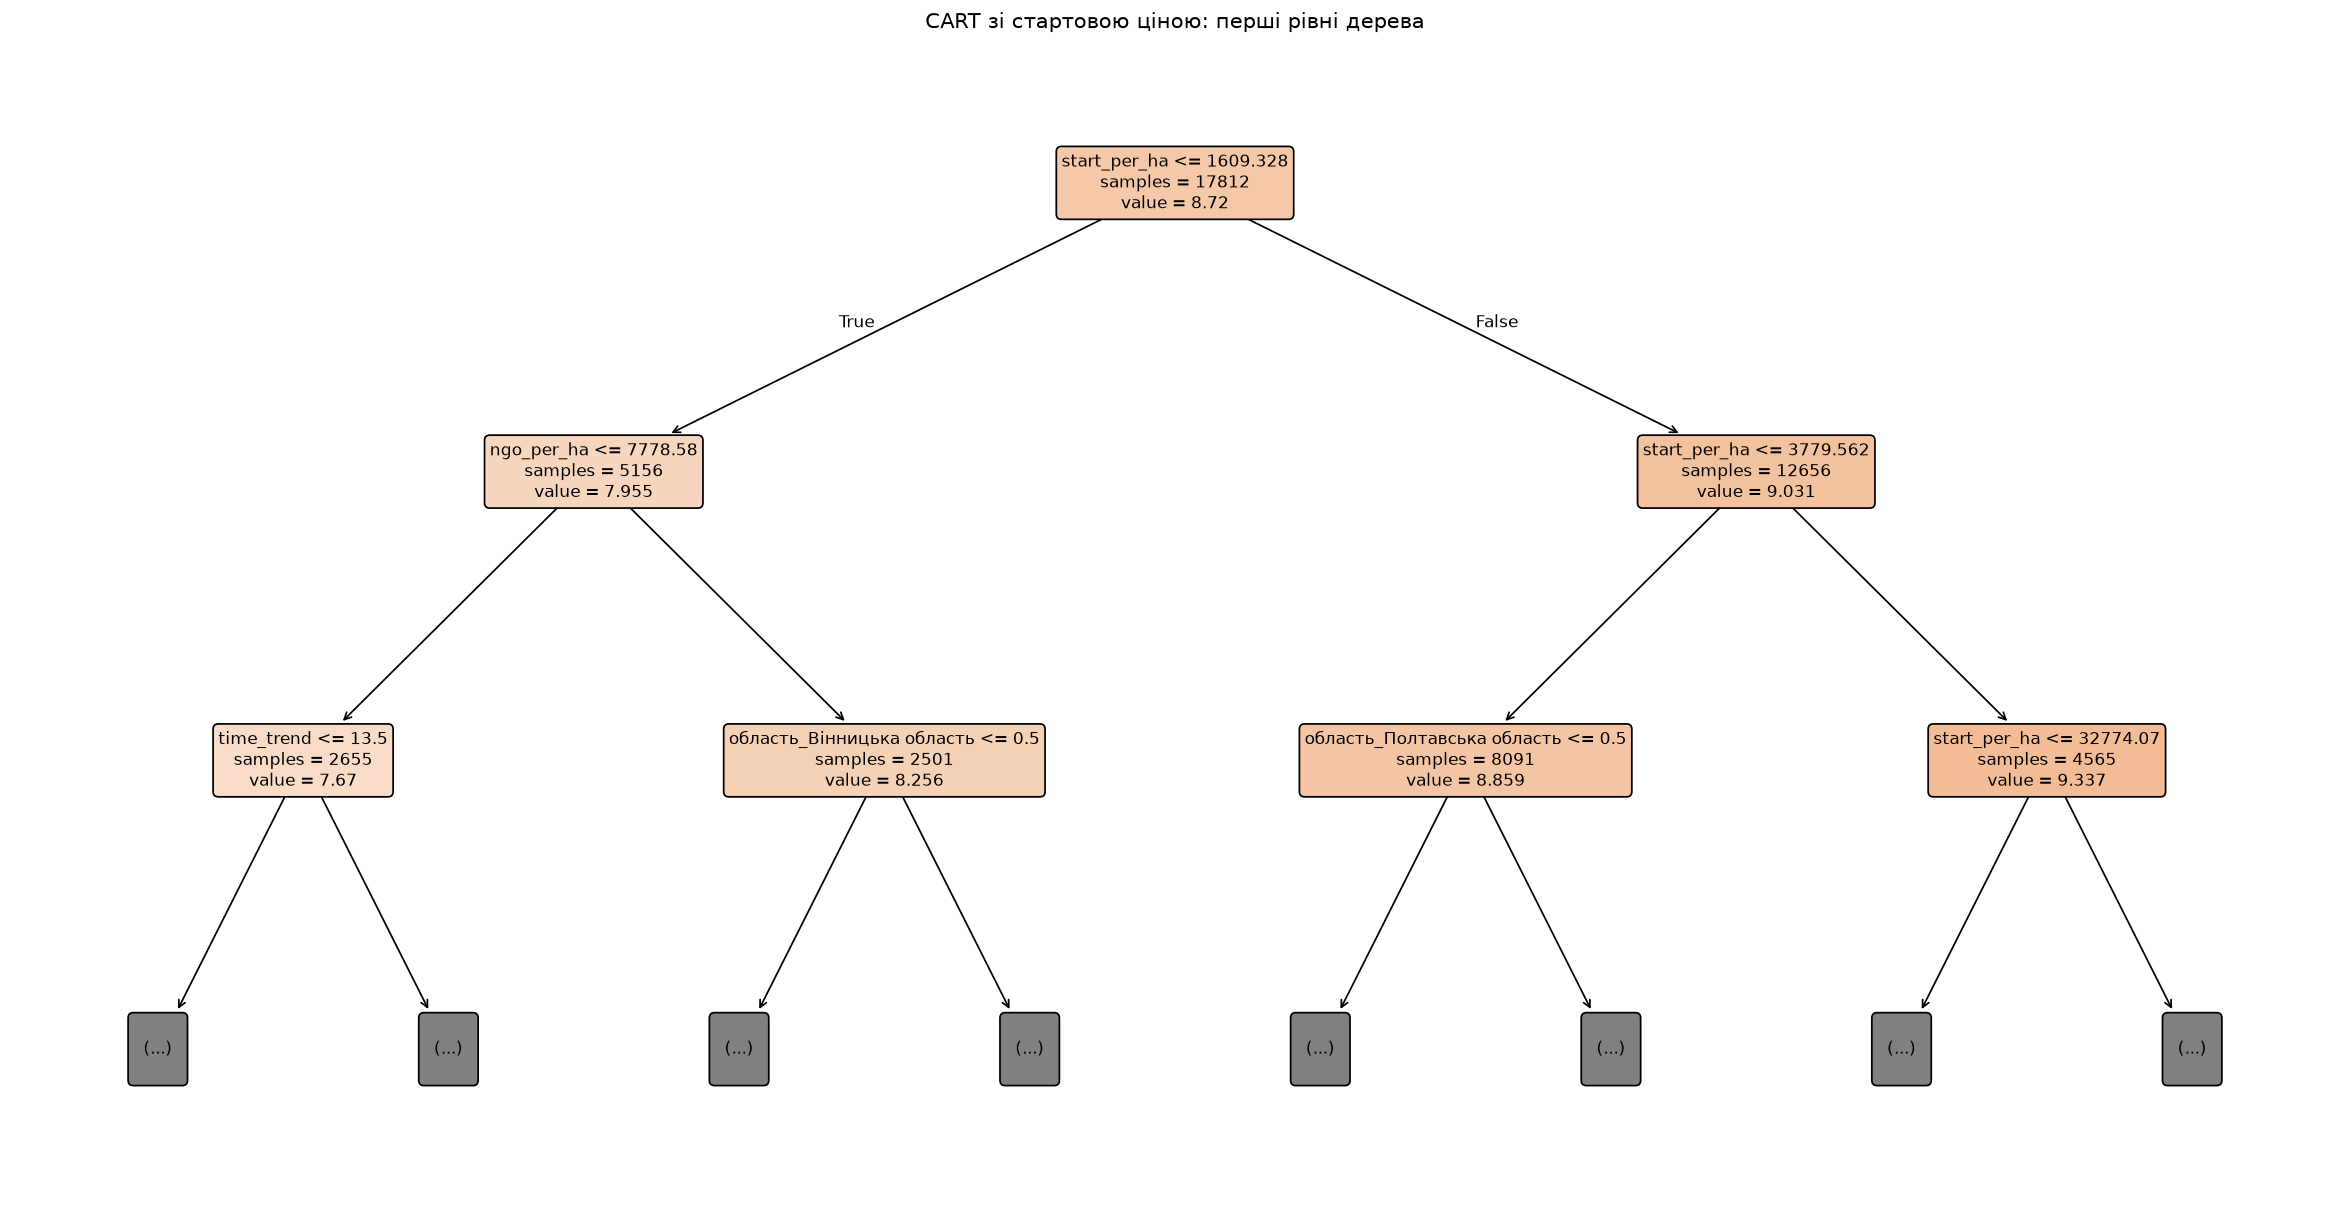

In [34]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(24, 12))

plot_tree(
    cart_with_start,
    feature_names=X_train_cart.columns.tolist(),
    max_depth=2,
    filled=True,
    rounded=True,
    impurity=False,
    fontsize=10
)

plt.title('CART зі стартовою ціною: перші рівні дерева')
plt.show()

Перше розбиття дерево здійснює за стартовою платою: **1609,33 грн/га**. На цьому кроці саме такий поділ найбільше зменшує навчальну суму квадратів помилок. Наступні розбиття використовують стартову ціну, НГО, часовий тренд, область та інші характеристики.
Використання стартової ціни у верхніх вузлах свідчить про її корисність для навчального поділу, але саме по собі не доводить покращення прогнозу на нових даних.
На графіку відображену глибину -- 2 дял наочності, проте модель використовує глибину -- **10**

### Результати

In [30]:
comparison = pd.concat([
    results.assign(Метод='OLS'),
    results_spline.assign(Метод='Сплайн'),
    results_cart.assign(Метод='CART')
], ignore_index=True)

comparison['Стартова ціна'] = ['Без старту', 'Зі стартом'] * 3
comparison = comparison[['Метод', 'Стартова ціна', 'MAE (log)', 'RMSE (log)']]
comparison

,Метод,Стартова ціна,MAE (log),RMSE (log)
0,OLS,Без старту,0.715573,0.887743
1,OLS,Зі стартом,0.705509,0.871626
2,Сплайн,Без старту,0.715573,0.887743
3,Сплайн,Зі стартом,0.701637,0.869622
4,CART,Без старту,0.694336,0.881310
5,CART,Зі стартом,0.685487,0.868929


In [33]:
improvements = []
for method, data in comparison.groupby('Метод', sort=False):
    without = data.iloc[0]
    with_start = data.iloc[1]
    improvements.append({
        'Метод': method,
        'Зменшення MAE, %': (1 - with_start['MAE (log)'] / without['MAE (log)']) * 100,
        'Зменшення RMSE, %': (1 - with_start['RMSE (log)'] / without['RMSE (log)']) * 100})
pd.DataFrame(improvements)

,Метод,"Зменшення MAE, %","Зменшення RMSE, %"
0,OLS,1.406405,1.815420
1,Сплайн,1.947447,2.041254
2,CART,1.274377,1.404849
